# Object Tracking
**Satya Mallick, LearnOpenCV.com**

- What is tracking?
- Tracking in computer vison.
- Motion model and appearnace model.
- OpenCV API Tracker Class.

# Goal

 Given the initial location of an object, track location in subsequent frames

![Object Tracking](https://learnopencv.com/wp-content/uploads/2023/03/opencv_bootcamp_NB11_race_car_tracking.png)

In [1]:
# Run setup before imports; OpenCV packages share cv2, so keep only contrib.
%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python-headless

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Let pip choose compatible wheels for this kernel's Python version.
%pip install --upgrade "opencv-contrib-python>=4.10" numpy matplotlib

# Restart the kernel after installation, then continue at the import cell.
print("Setup complete. Restart the kernel, then run from the import cell below.")

  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)
  Attempting uninstall: opencv-contrib-python
    Found existing installation: opencv-contrib-python 4.9.0.80
    Uninstalling opencv-contrib-python-4.9.0.80:
      Successfully uninstalled opencv-contrib-python-4.9.0.80
Note: you may need to restart the kernel to use updated packages.
Setup complete. Restart the kernel, then run from the import cell below.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Import the modules used below after completing setup and restarting the kernel.
import os
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve
from IPython.display import HTML, YouTubeVideo, display
from base64 import b64encode

%matplotlib inline

##  <font style="color:black">Download Assets</font>

In [4]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [5]:
URL = r"https://www.dropbox.com/s/ld535c8e0vueq6x/opencv_bootcamp_assets_NB11.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), "opencv_bootcamp_assets_NB11.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

# Tracker Class in OpenCV

1. BOOSTING
2. MIL
3. KCF
4. CRST
5. TLD
 * Tends to recover from occulusions
6. MEDIANFLOW
 * Good for predictable slow motion
7. GOTURN
 * Deep Learning based
 * Most Accurate
8. MOSSE
 * Fastest

In [6]:
video_id = "XkJCvtCRdVM"

HTML(f"""
<iframe
    width="560"
    height="315"
    src="https://www.youtube.com/embed/{video_id}"
    frameborder="0"
    referrerpolicy="strict-origin-when-cross-origin"
    allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture"
    allowfullscreen>
</iframe>
""")

In [7]:
video_input_file_name = "race_car.mp4"


def drawRectangle(frame, bbox):
    p1 = (int(bbox[0]), int(bbox[1]))
    p2 = (int(bbox[0] + bbox[2]), int(bbox[1] + bbox[3]))
    cv2.rectangle(frame, p1, p2, (255, 0, 0), 2, 1)


def displayRectangle(frame, bbox):
    plt.figure(figsize=(20, 10))
    frameCopy = frame.copy()
    drawRectangle(frameCopy, bbox)
    frameCopy = cv2.cvtColor(frameCopy, cv2.COLOR_RGB2BGR)
    plt.imshow(frameCopy)
    plt.axis("off")


def drawText(frame, txt, location, color=(50, 170, 50)):
    cv2.putText(frame, txt, location, cv2.FONT_HERSHEY_SIMPLEX, 1, color, 3)

# GOTURN Tracker

![](https://learnopencv.com/wp-content/uploads/2023/03/opencv_bootcamp_NB11_goturn.jpg)

# Create the Tracker instance

In [8]:
# Set up tracker
tracker_types = [
    "BOOSTING",
    "MIL",
    "KCF",
    "CSRT",
    "TLD",
    "MEDIANFLOW",
    "GOTURN",
    "MOSSE",
]

# Change the index to change the tracker type
tracker_type = tracker_types[3]

if tracker_type == 'BOOSTING':
    tracker = cv2.legacy.TrackerBoosting_create()
elif tracker_type == 'MIL':
    tracker = cv2.TrackerMIL_create()
elif tracker_type == 'KCF':
    tracker = cv2.TrackerKCF_create()
elif tracker_type == 'TLD':
    tracker = cv2.legacy.TrackerTLD_create()
elif tracker_type == 'MEDIANFLOW':
    tracker = cv2.legacy.TrackerMedianFlow_create()
elif tracker_type == 'GOTURN':
    tracker = cv2.TrackerGOTURN_create()
elif tracker_type == "CSRT":
    tracker = cv2.TrackerCSRT_create()
elif tracker_type == "MOSSE":
    tracker = cv2.legacy.TrackerMOSSE_create()
else:
    tracker = None

# Read input video & Setup output Video

In [9]:
# Read video
video = cv2.VideoCapture(video_input_file_name)
ok, frame = video.read()

# Exit if video not opened
if not video.isOpened():
    print("Could not open video")
    sys.exit()
else:
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

video_output_file_name = "race_car-" + tracker_type + ".mp4"
video_out = cv2.VideoWriter(video_output_file_name, cv2.VideoWriter_fourcc(*"XVID"), 10, (width, height))

video_output_file_name

'race_car-CSRT.mp4'

# Define Bounding Box

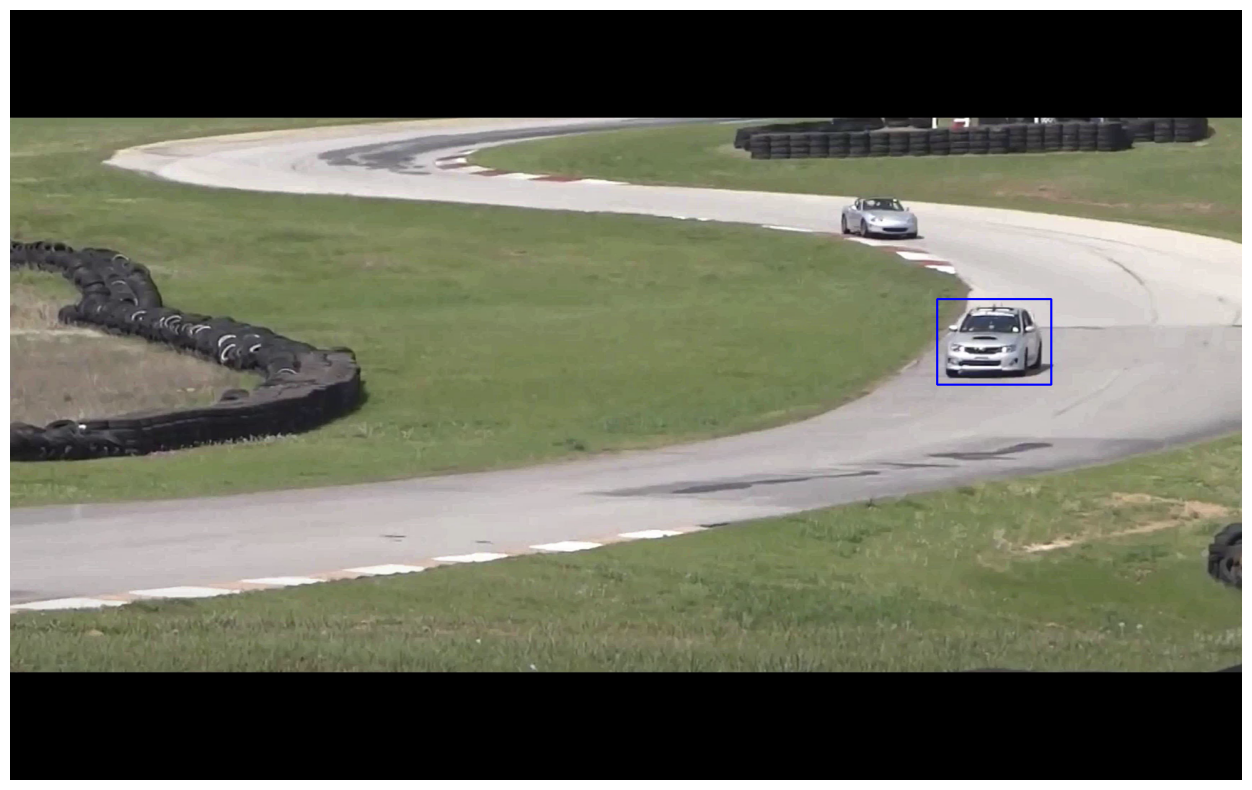

In [10]:
# Define a bounding box
bbox = (1300, 405, 160, 120)
# bbox = cv2.selectROI(frame, False)
# print(bbox)
displayRectangle(frame, bbox)

# Intilialize Tracker

1. One frame
2. A bounding box


In [11]:
# Initialize tracker with first frame and bounding box

ok = tracker.init(frame, bbox)

# Read frame and Track Object

In [12]:
while True:
    ok, frame = video.read()

    if not ok:
        break

    # Start timer
    timer = cv2.getTickCount()

    # Update tracker
    ok, bbox = tracker.update(frame)

    # Calculate Frames per second (FPS)
    fps = cv2.getTickFrequency() / (cv2.getTickCount() - timer)

    # Draw bounding box
    if ok:
        drawRectangle(frame, bbox)
    else:
        drawText(frame, "Tracking failure detected", (80, 140), (0, 0, 255))

    # Display Info
    drawText(frame, tracker_type + " Tracker", (80, 60))
    drawText(frame, "FPS : " + str(int(fps)), (80, 100))

    # Write frame to video
    video_out.write(frame)

video.release()
video_out.release()

In [ ]:
# Install portable FFmpeg into the notebook kernel's environment.
%pip install imageio-ffmpeg

from pathlib import Path
import shutil
import subprocess

# Resolve the same local output path used by VideoWriter.
tracking_path = Path(video_output_file_name).resolve()
if not tracking_path.is_file():
    raise FileNotFoundError(f"Run the tracking/writing cells first: {tracking_path}")
playback_path = tracking_path.with_name("race_car_track_x264.mp4")
ffmpeg_exe = shutil.which("ffmpeg")
if ffmpeg_exe is None:
    import imageio_ffmpeg
    ffmpeg_exe = imageio_ffmpeg.get_ffmpeg_exe()

# Encode H.264 for browser playback; argument lists handle paths with spaces.
subprocess.run(
    [ffmpeg_exe, "-y", "-i", str(tracking_path), "-c:v", "libx264",
     "-pix_fmt", "yuv420p", "-movflags", "+faststart", str(playback_path),
     "-hide_banner", "-loglevel", "error"],
    check=True,
)

Render MP4 Video

In [ ]:
from IPython.display import Video

# Embed the local MP4 produced by the conversion cell above.
Video(str(playback_path), embed=True, width=1024)

The expected video rendered in the above cell should be the same as the following.

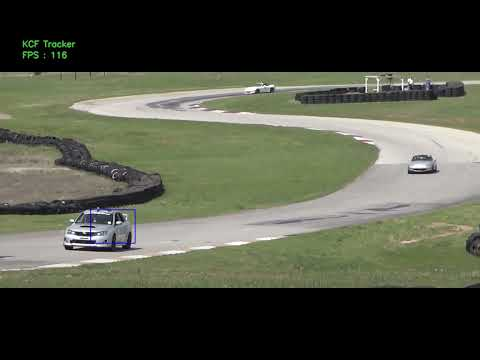

In [18]:
# Tracker: KCF
video = YouTubeVideo("pk3tmdRX4ww", width=1024, height=640)
display(video)

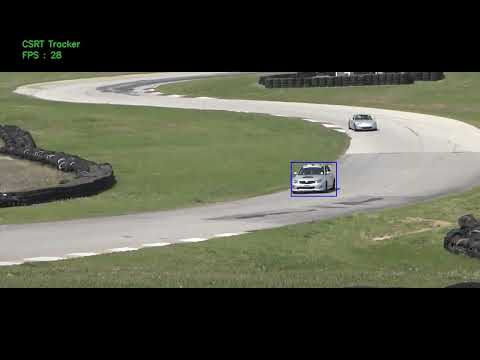

In [19]:
# Tracker: CSRT
video = YouTubeVideo("6gGDf-7ypBE", width=1024, height=640)
display(video)

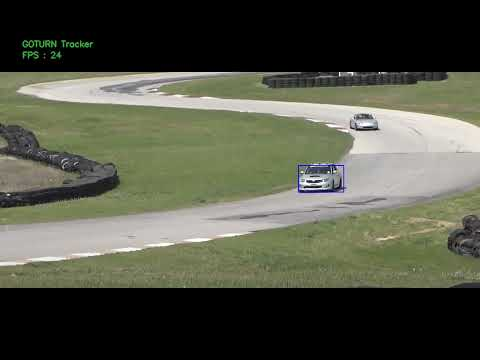

In [20]:
# Tracker: GOTURN
video = YouTubeVideo("0bnWxc4zMvY", width=1024, height=640)
display(video)

# Thank You!